In [1]:

from google.colab import files

uploaded = files.upload()


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv


In [2]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# Find the uploaded CSV automatically
csv_files = [f for f in os.listdir("/content") if f.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("Upload your dataset CSV first.")

print("Available CSV files:", csv_files)

# Use the uploaded dataset
file_path = "/content/" + csv_files[0]
df = pd.read_csv(file_path)

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))


Available CSV files: ['World_Energy_By_Country_And_Region_1965_to_2023.csv']

Dataset shape: (111, 60)

Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

First five rows:


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68



Missing values:


,Missing Values
Country,8
1965,8
1966,8
1967,8
1968,8
1969,8
1970,8
1971,8
1972,8
1973,8


In [4]:
# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Identify country column
if "country" in df.columns:
    country_col = "country"
else:
    raise ValueError("Country column not found. Available columns: " + str(df.columns.tolist()))

# Identify the year columns (columns that are numeric strings)
year_cols = [c for c in df.columns if c.isdigit()]

if not year_cols:
    raise ValueError("No year columns found in the dataset.")

# Reshape from wide format to long format
df_long = df.melt(
    id_vars=[country_col],
    value_vars=year_cols,
    var_name="year",
    value_name="primary_energy_consumption"
)

# Convert year to integer and clean energy consumption column
df_long["year"] = df_long["year"].astype(int)
df_long["primary_energy_consumption"] = pd.to_numeric(df_long["primary_energy_consumption"], errors="coerce")

# Clean country names to match target
df_long[country_col] = df_long[country_col].str.strip()

# Define target country and filter dataset
COUNTRY = "US"
df_country = df_long[df_long[country_col].str.lower() == COUNTRY.lower()].dropna().sort_values("year").reset_index(drop=True)

print(f"Data successfully reshaped for {COUNTRY}:")
print(df_country.head())
print(f"\nShape of filtered data: {df_country.shape}")

Data successfully reshaped for US:
  country  year  primary_energy_consumption
0      US  1965                       51.98
1      US  1966                       54.89
2      US  1967                       56.80
3      US  1968                       60.19
4      US  1969                       63.30

Shape of filtered data: (59, 3)


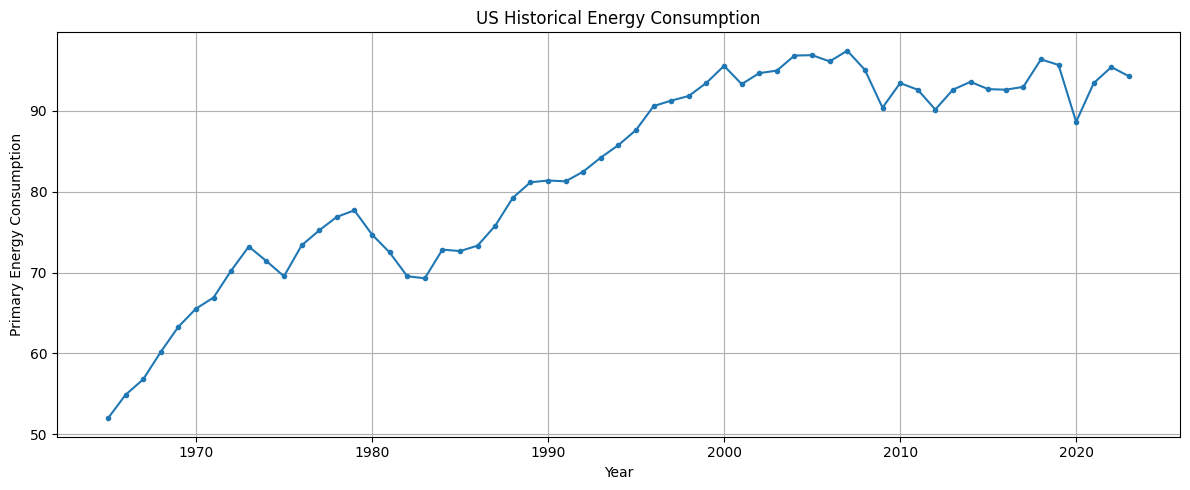

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_country["year"],
    df_country["primary_energy_consumption"],
    marker="o",
    markersize=3
)

plt.title(f"{COUNTRY} Historical Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Primary Energy Consumption")
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:

WINDOW_SIZE = 5
TRAIN_RATIO = 0.80

values = df_country["primary_energy_consumption"].to_numpy(dtype=float)
years = df_country["year"].to_numpy()

if len(values) < 15:
    raise ValueError(
        "Not enough yearly records for this experiment. "
        "Select a country with more historical data."
    )

# Split chronologically
split_idx = int(len(values) * TRAIN_RATIO)

if split_idx <= WINDOW_SIZE or split_idx >= len(values):
    raise ValueError("Not enough data for the train-test split.")

# Fit scaler only on training observations
scaler = MinMaxScaler()
scaler.fit(values[:split_idx].reshape(-1, 1))

scaled_values = scaler.transform(
    values.reshape(-1, 1)
).flatten()

X_train, y_train = [], []
X_test, y_test = [], []
test_years = []

for i in range(WINDOW_SIZE, len(values)):

    # Require five consecutive input years and a consecutive target year
    sequence_years = years[i - WINDOW_SIZE:i + 1]

    if not np.all(np.diff(sequence_years) == 1):
        continue

    X_seq = scaled_values[i - WINDOW_SIZE:i]
    y_value = scaled_values[i]

    if i < split_idx:
        X_train.append(X_seq)
        y_train.append(y_value)
    else:
        X_test.append(X_seq)
        y_test.append(y_value)
        test_years.append(years[i])

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

X_test = np.array(X_test, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError(
        "No valid train/test sequences were created. "
        "Check annual gaps and country records."
    )

# LSTM input: samples, time steps, features
X_train = X_train.reshape(-1, WINDOW_SIZE, 1)
X_test = X_test.reshape(-1, WINDOW_SIZE, 1)

print("Training sequences:", X_train.shape)
print("Training targets:", y_train.shape)
print("Testing sequences:", X_test.shape)
print("Testing targets:", y_test.shape)


Training sequences: (42, 5, 1)
Training targets: (42,)
Testing sequences: (12, 5, 1)
Testing targets: (12,)


In [9]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, 1)),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.20,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed.")


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - loss: 0.3872 - val_loss: 0.7909
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.3420 - val_loss: 0.7443
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.3208 - val_loss: 0.6970
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.2965 - val_loss: 0.6443
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2701 - val_loss: 0.5871
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.2420 - val_loss: 0.5251
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2099 - val_loss: 0.4446
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1707 - val_loss: 0.3536
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1291 - val_loss: 0.2589
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0879 - val_loss: 0.1676
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0504 - val_loss: 0.0837
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0202 - val_lo

In [12]:
# Predict normalized test values
pred_scaled = model.predict(X_test, verbose=0)

# Convert to original energy-consumption units
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred_actual = scaler.inverse_transform(
    pred_scaled
).flatten()

# Evaluation metrics
mae = mean_absolute_error(
    y_test_actual, y_pred_actual
)

rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_pred_actual)
)

print("========== MODEL EVALUATION ==========")
print("Country:", COUNTRY)
print("Target:", "primary_energy_consumption")
print("Test observations:", len(y_test_actual))
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

results = pd.DataFrame({
    "Year": test_years,
    "Actual Consumption": y_test_actual,
    "Predicted Consumption": y_pred_actual
})

display(results)

results.to_csv(
    "/content/energy_forecasting_results.csv",
    index=False
)

========== MODEL EVALUATION ==========
Country: US
Target: primary_energy_consumption
Test observations: 12
MAE:  1.5544
RMSE: 2.2488


,Year,Actual Consumption,Predicted Consumption
0,2012,90.170006,93.833946
1,2013,92.619995,92.780205
2,2014,93.590004,92.279625
3,2015,92.690002,92.700745
4,2016,92.619995,92.569481
5,2017,92.970009,92.582466
6,2018,96.370003,93.047012
7,2019,95.680000,93.420441
8,2020,88.639999,93.682281
9,2021,93.439995,93.483002


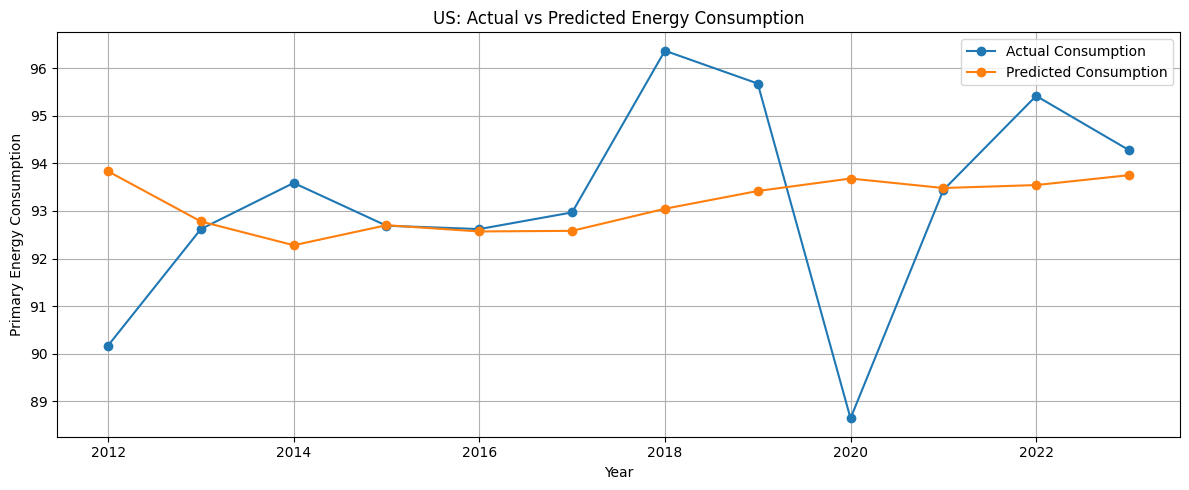

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    results["Year"],
    results["Actual Consumption"],
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    results["Year"],
    results["Predicted Consumption"],
    marker="o",
    label="Predicted Consumption"
)

plt.title(f"{COUNTRY}: Actual vs Predicted Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Primary Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:

# Use the final five consecutive years
if np.all(np.diff(years[-WINDOW_SIZE:]) == 1):

    last_five = scaled_values[-WINDOW_SIZE:]

    next_input = last_five.reshape(
        1, WINDOW_SIZE, 1
    )

    next_scaled = model.predict(next_input, verbose=0)

    next_prediction = scaler.inverse_transform(
        next_scaled
    )[0, 0]

    next_year = int(years[-1] + 1)

    print("Country:", COUNTRY)
    print("Last available year:", years[-1])
    print("Forecast year:", next_year)
    print(
        f"Predicted energy consumption: {next_prediction:.4f}"
    )

else:
    print(
        "Cannot forecast the next year: "
        "the final five records are not consecutive annual observations."
    )


Country: US
Last available year: 2023
Forecast year: 2024
Predicted energy consumption: 93.3483


In [17]:

from google.colab import files

files.download("/content/energy_forecasting_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>